Cellule 1 — connecter la nouvelle application au cluster

In [1]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("spark://spark-master:7077")
    .appName("Bilal-Partie2-RDD")
    .getOrCreate()
)

sc = spark.sparkContext
sc.setLogLevel("WARN")
print(sc.appName, sc.master)

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/15 12:29:25 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Bilal-Partie2-RDD spark://spark-master:7077


Cellule 2 — lire et parser les événements depuis MinIO

In [2]:
import json

history_path = "s3a://lake/bronze/history/orders_history.jsonl"

lines = sc.textFile(history_path, minPartitions=4)
orders = lines.map(json.loads)

total = orders.count()
print(f"Événements lus depuis MinIO : {total:,}")
print(f"Partitions du RDD : {orders.getNumPartitions()}")

assert total == 50_000

26/11/15 12:29:32 WARN MetricsConfig: Cannot locate configuration: tried hadoop-metrics2-s3a-file-system.properties,hadoop-metrics2.properties
[Stage 0:>                                                          (0 + 2) / 4]

Événements lus depuis MinIO : 50,000
Partitions du RDD : 4


Cellule 3 — préparer le RDD des livraisons

In [3]:
delivered = orders.filter(lambda order: order["status"] == "DELIVERED")
print(delivered.take(1))

[{'order_id': 'ORD-00000001', 'restaurant_id': 'REST-0016', 'customer_id': 'CUSTOMER-01729', 'city': 'Casablanca', 'status': 'DELIVERED', 'amount_mad': 137.47, 'items_count': 2, 'distance_km': 3.56, 'courier_id': 'COURIER-027', 'event_time': '2026-10-16T12:25:30Z'}]


Cellule 4 — Chiffre d’affaires par ville avec reduceByKey()

In [4]:
from decimal import Decimal
from operator import add

amounts_by_city = delivered.map(
    lambda order: (order["city"], Decimal(str(order["amount_mad"])))
)

revenue_by_city = amounts_by_city.reduceByKey(add)

sc.setJobGroup("partie2-ca", "Partie 2 - Chiffre d'affaires par ville")
city_revenues = sorted(revenue_by_city.collect())

for city, revenue in city_revenues:
    print(f"{city:<15} {revenue:>12,.2f} MAD")

total_revenue = sum(revenue for city, revenue in city_revenues)
print(f"\nCA total : {total_revenue:,.2f} MAD")

[Stage 2:=============================>                             (2 + 2) / 4]

Agadir            652,425.87 MAD
Casablanca        674,623.47 MAD
Fes               649,302.42 MAD
Kenitra           611,900.92 MAD
Marrakech         643,253.72 MAD
Meknes            672,146.25 MAD
Rabat             651,503.03 MAD
Sale              627,851.05 MAD
Tanger            686,379.69 MAD
Tetouan           645,551.40 MAD

CA total : 6,514,937.82 MAD


Cellule 5 — Panier moyen par ville avec aggregateByKey()

In [5]:
def add_amount(accumulator, amount):
    subtotal, count = accumulator
    return subtotal + amount, count + 1


def merge_totals(left, right):
    return left[0] + right[0], left[1] + right[1]


city_stats = amounts_by_city.aggregateByKey(
    (Decimal("0.00"), 0),
    add_amount,
    merge_totals,
)

rows = sorted(city_stats.collect())

print(f"{'Ville':<15} {'Livraisons':>10} {'CA (MAD)':>15} {'Panier moyen (MAD)':>20}")
for city, (revenue, count) in rows:
    print(f"{city:<15} {count:>10} {revenue:>15,.2f} {revenue / count:>20,.2f}")

print(f"\nTotal des événements DELIVERED : {sum(count for _, (_, count) in rows)}")

Ville           Livraisons        CA (MAD)   Panier moyen (MAD)
Agadir                2751      652,425.87               237.16
Casablanca            2810      674,623.47               240.08
Fes                   2747      649,302.42               236.37
Kenitra               2594      611,900.92               235.89
Marrakech             2726      643,253.72               235.97
Meknes                2796      672,146.25               240.40
Rabat                 2704      651,503.03               240.94
Sale                  2673      627,851.05               234.89
Tanger                2835      686,379.69               242.11
Tetouan               2724      645,551.40               236.99

Total des événements DELIVERED : 27360


Cellule 6 — Top 5 des restaurants

In [6]:
deliveries_by_restaurant = (
    delivered
    .map(lambda order: (order["restaurant_id"], 1))
    .reduceByKey(add)
)

top_5 = deliveries_by_restaurant.takeOrdered(
    5,
    key=lambda item: (-item[1], item[0]),
)

for rank, (restaurant_id, count) in enumerate(top_5, start=1):
    print(f"{rank}. {restaurant_id} — {count} livraisons")

1. REST-0002 — 167 livraisons
2. REST-0115 — 167 livraisons
3. REST-0017 — 164 livraisons
4. REST-0082 — 162 livraisons
5. REST-0015 — 161 livraisons


Cellule 7 — Lineage et capture du DAG

In [7]:
print(revenue_by_city.toDebugString().decode("utf-8"))

(4) PythonRDD[8] at collect at /tmp/ipykernel_45/1130147613.py:11 []
 |  MapPartitionsRDD[7] at mapPartitions at PythonRDD.scala:160 []
 |  ShuffledRDD[6] at partitionBy at NativeMethodAccessorImpl.java:0 []
 +-(4) PairwiseRDD[5] at reduceByKey at /tmp/ipykernel_45/1130147613.py:8 []
    |  PythonRDD[4] at reduceByKey at /tmp/ipykernel_45/1130147613.py:8 []
    |  s3a://lake/bronze/history/orders_history.jsonl MapPartitionsRDD[1] at textFile at NativeMethodAccessorImpl.java:0 []
    |  s3a://lake/bronze/history/orders_history.jsonl HadoopRDD[0] at textFile at NativeMethodAccessorImpl.java:0 []


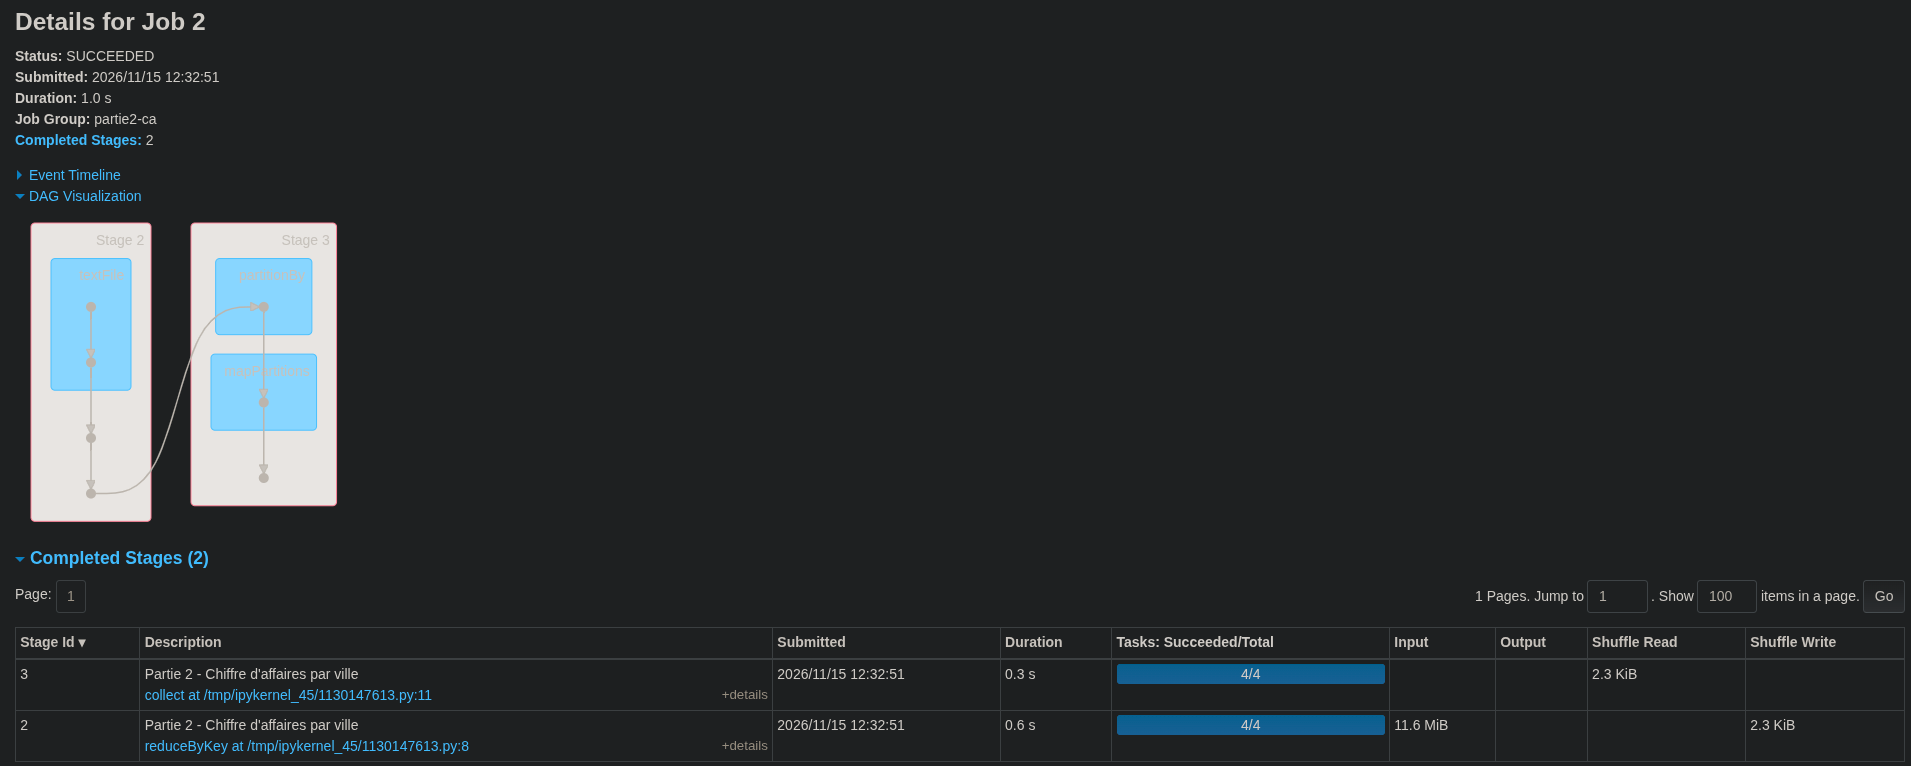

map(), filter(), reduceByKey() et aggregateByKey() sont des transformations différées. Les actions count(), take(), collect() et takeOrdered() déclenchent les calculs. Dans notre lineage, ShuffledRDD correspond à la redistribution des sommes partielles par ville. Si un Executor perd une partition, Spark peut la recalculer en suivant ses dépendances, à partir des données sources conservées dans MinIO.

In [8]:
spark.stop()